# Golden window - which X range makes a batch fail QC, with statistical evidence

**Golden** = every Y inside `config.GOLDEN_SPEC` (Kappa 8-10, Viscosity 700-800, confirmed 2026-10-28).
Each X is tested for each **fail mode**, because one X can push two Y the same or opposite ways.

| Step | What | Why it is evidence |
|---|---|---|
| 1 | Fail rate per quintile of X (Wilson 95% CI) | shows *where* the fail rate jumps |
| 2 | Best cut + risk ratio + **permutation p** (outcome shuffled inside each month) | the p already pays for searching the cut, and the season cannot create it |
| 3 | **Mantel-Haenszel by month** + months that agree | same rule inside every month -> not a season effect |
| 4 | Cut from the early months, checked on the **later months** | the rule works on data it never saw |
| 5 | **Benjamini-Hochberg** q over all X | many X tested -> control false finds |
| 6 | Share on the bad side now, fail rate if moved; combined window check | what to control and what it is worth |

**Grade A** = 5 + 3 + 4 + every month agrees · **B** = 5 + (3 or 4) · **C** = 5 only · **-** = not significant.
Observational data: grade A is strong enough to propose a **trial**, not to prove cause.

Edit X in `config.FEATURES` / `config.GOLDEN_EXTRA`, the combined window in `config.GOLDEN_WINDOW_RULES`. No PI access.

In [10]:
import importlib
import pandas as pd

import config, data, golden, plots
for mod in (config, data, golden, plots):
    importlib.reload(mod)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 40)

## Step 0 - Data and why batches fail
A batch can fail more than one way, so the modes add up to more than `fail`.

In [11]:
df = golden.load_golden()
overall, by_month = golden.fail_modes(df)
display(overall)
display(by_month)

golden data: 56 batches with Kappa + Viscosity (2026-05-21 .. 2026-05-30), golden 37 (66%)


,batches,share
fail,19.0,0.339
kappa_high,17.0,0.304
kappa_low,1.0,0.018
visc_high,3.0,0.054
visc_low,0.0,0.000


,n,fail,kappa_high,kappa_low,visc_high,visc_low
month,,,,,,
2026-05,56,0.34,0.3,0.02,0.05,0.0


## Outliers of X
Setting: `config.GOLDEN_OUTLIER` = `None` (keep all, default) / `"2sd"` / `"iqr3"`, removed **one X at a time** and per digester.
- Table 1: how many values each method would remove (high `skew` -> 2 SD is a poor rule, it only cuts the long side).
- Table 2 (**sensitivity**): the same threshold test with no / 2 SD / 3 IQR removal for the window X. If the cut, fail rates and months barely move, the result does not come from outliers.

In [12]:
print("GOLDEN_OUTLIER =", config.GOLDEN_OUTLIER, "| by digester:", config.GOLDEN_OUTLIER_BY_DIGESTER)
display(golden.outlier_report(df))
for col, _, _ in config.GOLDEN_WINDOW_RULES:
    print(f"Sensitivity - {golden.golden_features(df).get(col, col)} (Fail QC any)")
    display(golden.sensitivity(df, col, "fail"))

GOLDEN_OUTLIER = None | by digester: True


,n,skew,min,median,max,removed_2sd,removed_iqr3
X,,,,,,,
Alkali conc 1,56,-2.4,35.318,36.489,36.596,4,4
P-factor,56,-0.4,295.498,333.704,359.647,2,0
H&C minutes,56,0.0,20.000,30.000,35.000,2,11
WL / t chip,56,1.5,0.134,0.150,0.201,3,0
L:W,56,-0.1,1.158,1.630,1.989,3,0
LP pressure,56,-0.4,5.897,6.566,7.129,3,2
P-factor rate,56,0.2,4.025,4.820,5.949,3,2
P-temp max,56,1.4,167.107,168.725,173.907,1,2
P-temp SP,40,-0.8,165.000,166.000,166.000,0,0


Sensitivity - P-factor overshoot (Fail QC any)


,n,removed,bad side,fail bad / good,RR,p perm,MH RR,months agree
outliers,,,,,,,,
keep all,56,0,<= 68.45,50% / 25%,2.00,0.248,2.00,1/1
2sd,52,4,<= 72.98,50% / 20%,2.50,0.066,2.50,1/1
iqr3,54,2,<= 68.51,50% / 24%,2.12,0.138,2.13,1/1


Sensitivity - H-factor (Fail QC any)


,n,removed,bad side,fail bad / good,RR,p perm,MH RR,months agree
outliers,,,,,,,,
keep all,56,0,<= 394.4,48% / 24%,1.97,0.242,1.97,1/1
2sd,53,3,<= 397.5,43% / 23%,1.86,0.377,1.86,1/1
iqr3,56,0,<= 394.4,48% / 24%,1.97,0.242,1.97,1/1


## Steps 1-5 - Screen every X for every fail mode
How to read one row of the summary:
- **Bad side** `<= 64.3` -> batches with X at or below 64.3 fail more. *Cut 90% range* = how much the cut moves in a week-block bootstrap.
- **Fail % at bad side / Fail % at good side** -> both are FAIL rates: on the side that fails more (bad) and on the other side (good). **RR** = how many times more likely on the bad side.
- **p perm (q)** -> chance of a cut this strong by luck *within the same month*; q = after BH.
- **MH RR by month / Months agree** -> the effect after removing the season, and in how many months it points the same way.
- **Future fail % at bad / good side, Future p** -> cut found on the early months, fail rates in the later months.
- **Fail now -> if moved** -> fail rate if every bad-side batch moved to the good side (month-adjusted, upper estimate).

In [13]:
results = {}
for event in golden.OUTCOMES:
    res, _ = golden.screen(df, event, progress=False)
    results[event] = res
    print()
    print(f"===== {golden.OUTCOMES[event]}  (overall {df[event].mean():.0%}) =====")
    display(golden.summary(res))


===== Fail QC (any)  (overall 34%) =====


,X,Grade,Bad side,Cut 90% range,Fail % at bad side,Fail % at good side,RR [95% CI],p perm (q),MH RR by month,Months agree,Future fail % at bad side,Future fail % at good side,Future p,On bad side now,Fail now -> if moved
0,LP pressure,B,<= 6.571,6.571 - 6.592,62% (<= 6.571),4% (> 6.571),16.76 [2.40-117.12],0.001 (0.016),16.76 (p 0.004),1/1,-,-,-,52%,34% -> 4%
1,P-factor rate,-,> 4.702,4.645 - 4.73,47% (> 4.702),10% (<= 4.702),4.72 [1.21-18.39],0.027 (0.216),4.72 (p 0.025),1/1,-,-,-,64%,34% -> 10%
2,Chip weight,-,> 91.15,89.73 - 91.34,52% (> 91.15),23% (<= 91.15),2.29 [1.10-4.77],0.092 (0.341),2.29 (p 0.027),1/1,-,-,-,38%,34% -> 23%
3,P-factor final,-,<= 428.5,428.4 - 449.4,52% (<= 428.5),23% (> 428.5),2.29 [1.10-4.77],0.110 (0.341),2.29 (p 0.027),1/1,-,-,-,38%,34% -> 23%
4,Prehyd minutes,-,<= 69.73,69.38 - 69.73,48% (<= 69.73),21% (> 69.73),2.33 [1.03-5.25],0.129 (0.341),2.33 (p 0.042),1/1,-,-,-,48%,34% -> 21%
5,H&C minutes,-,<= 25,25 - 25,45% (<= 25),26% (> 25),1.72 [0.83-3.54],0.149 (0.341),1.72 (p 0.143),1/1,-,-,-,39%,34% -> 26%
6,Alkali / t chip,-,<= 5.509,5.384 - 5.509,45% (<= 5.509),20% (> 5.509),2.26 [0.94-5.42],0.167 (0.341),2.26 (p 0.068),1/1,-,-,-,55%,34% -> 20%
7,WL / t chip,-,<= 0.151,0.1478 - 0.151,45% (<= 0.151),20% (> 0.151),2.26 [0.94-5.42],0.172 (0.341),2.26 (p 0.068),1/1,-,-,-,55%,34% -> 20%
8,L:W,-,<= 1.541,1.54 - 1.541,50% (<= 1.541),25% (> 1.541),2.00 [0.98-4.09],0.211 (0.341),2.00 (p 0.058),1/1,-,-,-,36%,34% -> 25%
9,P-factor overshoot,-,<= 68.45,68.45 - 89.38,50% (<= 68.45),25% (> 68.45),2.00 [0.98-4.09],0.235 (0.341),2.00 (p 0.058),1/1,-,-,-,36%,34% -> 25%



===== Kappa high  (overall 30%) =====


,X,Grade,Bad side,Cut 90% range,Fail % at bad side,Fail % at good side,RR [95% CI],p perm (q),MH RR by month,Months agree,Future fail % at bad side,Future fail % at good side,Future p,On bad side now,Fail now -> if moved
0,LP pressure,B,<= 6.571,6.571 - 6.592,55% (<= 6.571),4% (> 6.571),14.90 [2.12-104.82],0.001 (0.016),14.90 (p 0.007),1/1,-,-,-,52%,30% -> 4%
1,P-factor rate,-,> 4.825,4.73 - 4.825,48% (> 4.825),14% (<= 4.825),3.49 [1.30-9.40],0.023 (0.128),3.49 (p 0.013),1/1,-,-,-,48%,30% -> 14%
2,Prehyd minutes,-,<= 69.73,69.38 - 69.73,48% (<= 69.73),14% (> 69.73),3.49 [1.30-9.40],0.024 (0.128),3.49 (p 0.013),1/1,-,-,-,48%,30% -> 14%
3,H&C minutes,-,<= 25,25 - 25,45% (<= 25),21% (> 25),2.21 [0.99-4.93],0.070 (0.280),2.21 (p 0.053),1/1,-,-,-,39%,30% -> 21%
4,H-factor,-,<= 394.4,394.4 - 611.2,48% (<= 394.4),18% (> 394.4),2.63 [1.14-6.09],0.095 (0.304),2.63 (p 0.024),1/1,-,-,-,41%,30% -> 18%
5,P-factor final,-,<= 428.5,428.4 - 449.4,48% (<= 428.5),20% (> 428.5),2.38 [1.07-5.30],0.130 (0.346),2.38 (p 0.034),1/1,-,-,-,38%,30% -> 20%
6,P-factor,-,<= 336.7,327.7 - 336.7,41% (<= 336.7),17% (> 336.7),2.44 [0.91-6.55],0.219 (0.500),2.44 (p 0.077),1/1,-,-,-,57%,30% -> 17%
7,P-factor overshoot,-,<= 68.45,68.45 - 89.38,45% (<= 68.45),22% (> 68.45),2.03 [0.93-4.42],0.279 (0.535),2.02 (p 0.076),1/1,-,-,-,36%,30% -> 22%
8,P-temp overshoot,-,> 2.786,2.786 - 3.251,45% (> 2.786),25% (<= 2.786),1.80 [0.73-4.43],0.315 (0.535),1.80 (p 0.201),1/1,-,-,-,50%,30% -> 20%
9,Chip weight,-,> 91.15,89.73 - 91.15,43% (> 91.15),23% (<= 91.15),1.88 [0.86-4.11],0.366 (0.535),1.88 (p 0.116),1/1,-,-,-,38%,30% -> 23%



===== Viscosity high  (overall 5%) =====


,X,Grade,Bad side,Cut 90% range,Fail % at bad side,Fail % at good side,RR [95% CI],p perm (q),MH RR by month,Months agree,Future fail % at bad side,Future fail % at good side,Future p,On bad side now,Fail now -> if moved
0,P-factor overshoot,-,<= 68.45,64.8 - 68.45,15% (<= 68.45),0% (> 68.45),inf [inf-inf],0.077 (0.511),nan (p nan),1/1,-,-,-,36%,5% -> 0%
1,P-factor final,-,<= 428.1,423.7 - 428.1,15% (<= 428.1),0% (> 428.1),inf [inf-inf],0.088 (0.511),nan (p nan),1/1,-,-,-,36%,5% -> 0%
2,LP pressure,-,<= 6.514,6.443 - 6.514,15% (<= 6.514),0% (> 6.514),inf [inf-inf],0.096 (0.511),nan (p nan),1/1,-,-,-,36%,5% -> 0%
3,H-factor,-,<= 414,353.4 - 414,11% (<= 414),0% (> 414),inf [inf-inf],0.212 (0.847),nan (p nan),1/1,-,-,-,48%,5% -> 0%
4,P-factor,-,<= 337.1,336.7 - 337.1,9% (<= 337.1),0% (> 337.1),inf [inf-inf],0.404 (0.970),nan (p nan),1/1,-,-,-,61%,5% -> 0%
5,P-temp overshoot,-,> 2.786,2.786 - 3.157,10% (> 2.786),0% (<= 2.786),inf [inf-inf],0.479 (0.970),nan (p nan),1/1,-,-,-,50%,5% -> 0%
6,P-factor rate,-,> 4.702,4.645 - 4.702,8% (> 4.702),0% (<= 4.702),inf [inf-inf],0.511 (0.970),nan (p nan),1/1,-,-,-,64%,5% -> -0%
7,P-temp max,-,<= 168.4,168.3 - 168.4,10% (<= 168.4),3% (> 168.4),3.60 [0.35-37.28],0.752 (0.970),3.60 (p 0.283),1/1,-,-,-,36%,5% -> 3%
8,Prehyd minutes,-,<= 69.27,68.33 - 69.27,10% (<= 69.27),3% (> 69.27),3.60 [0.35-37.28],0.763 (0.970),3.60 (p 0.283),1/1,-,-,-,36%,5% -> 3%
9,WL / t chip,-,<= 0.1476,0.1449 - 0.1476,10% (<= 0.1476),3% (> 0.1476),3.60 [0.35-37.28],0.764 (0.970),3.60 (p 0.283),1/1,-,-,-,36%,5% -> 3%



===== Viscosity low  (overall 0%) =====


""


### Step 1 picture - fail rate per quintile of the top X
Orange = bins on the bad side of the cut. Error bars = Wilson 95% CI. Bars that overlap the dashed line are not different from average.

ValueError: 'yerr' must not contain negative values

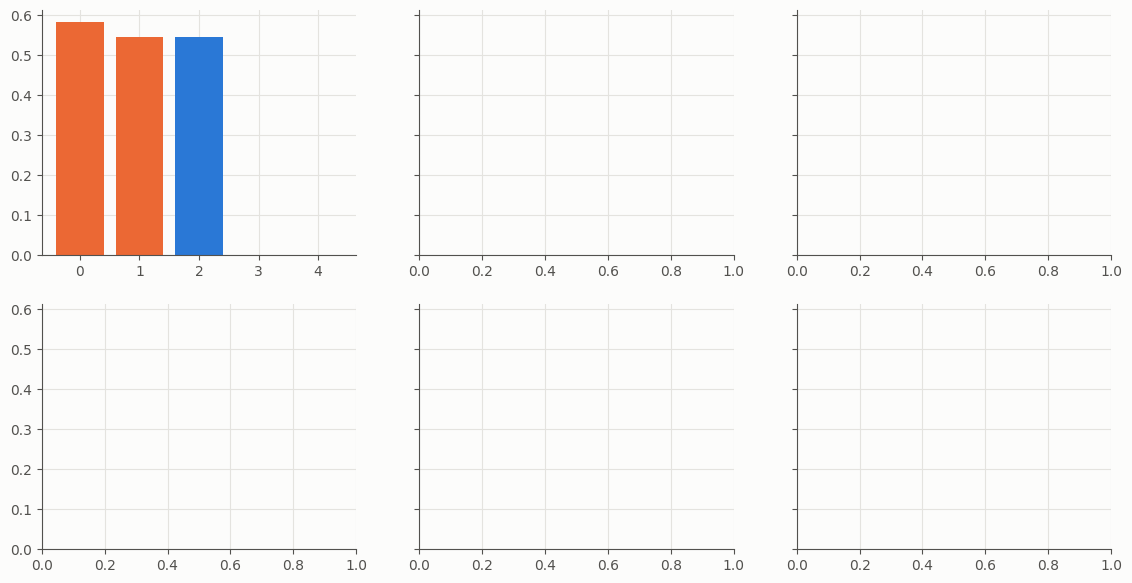

In [14]:
for event in ["fail", "kappa_high", "visc_high"]:
    plots.fail_curves(df, results[event], event)

  saved d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\golden_counts_fail.png
  saved d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\golden_counts_kappa_high.png
  saved d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\golden_counts_visc_high.png


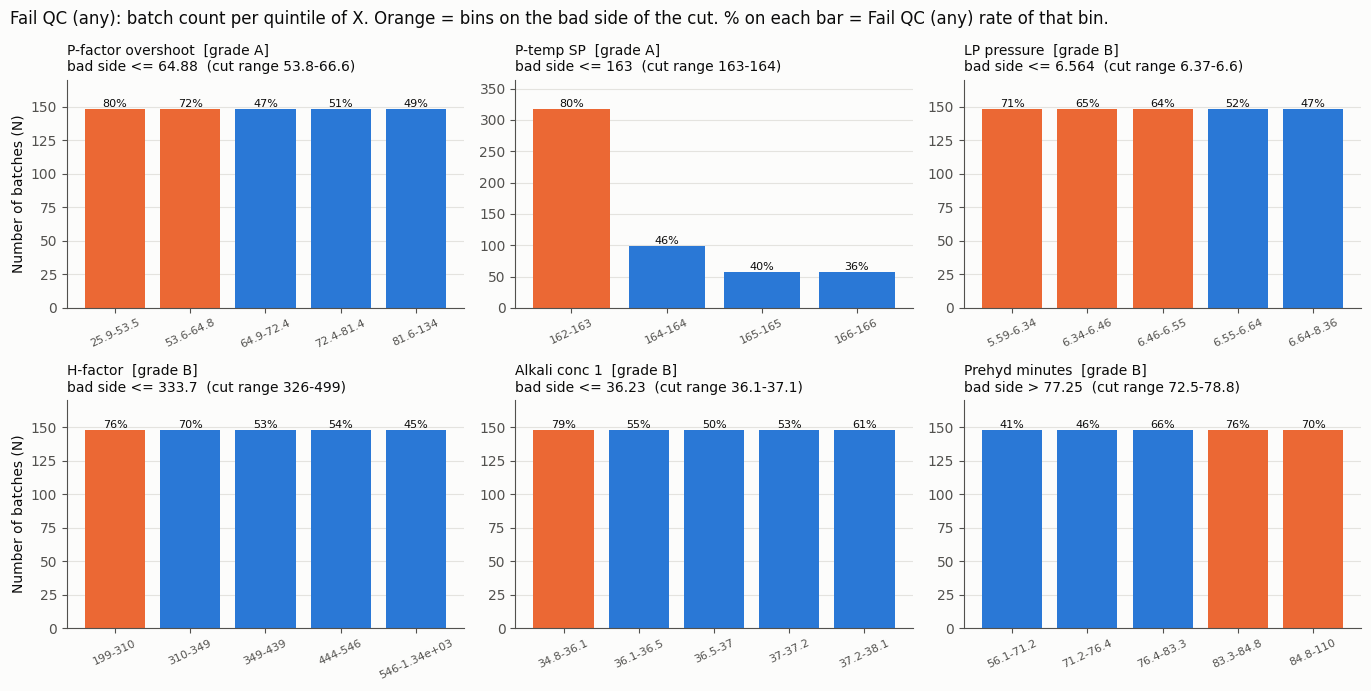

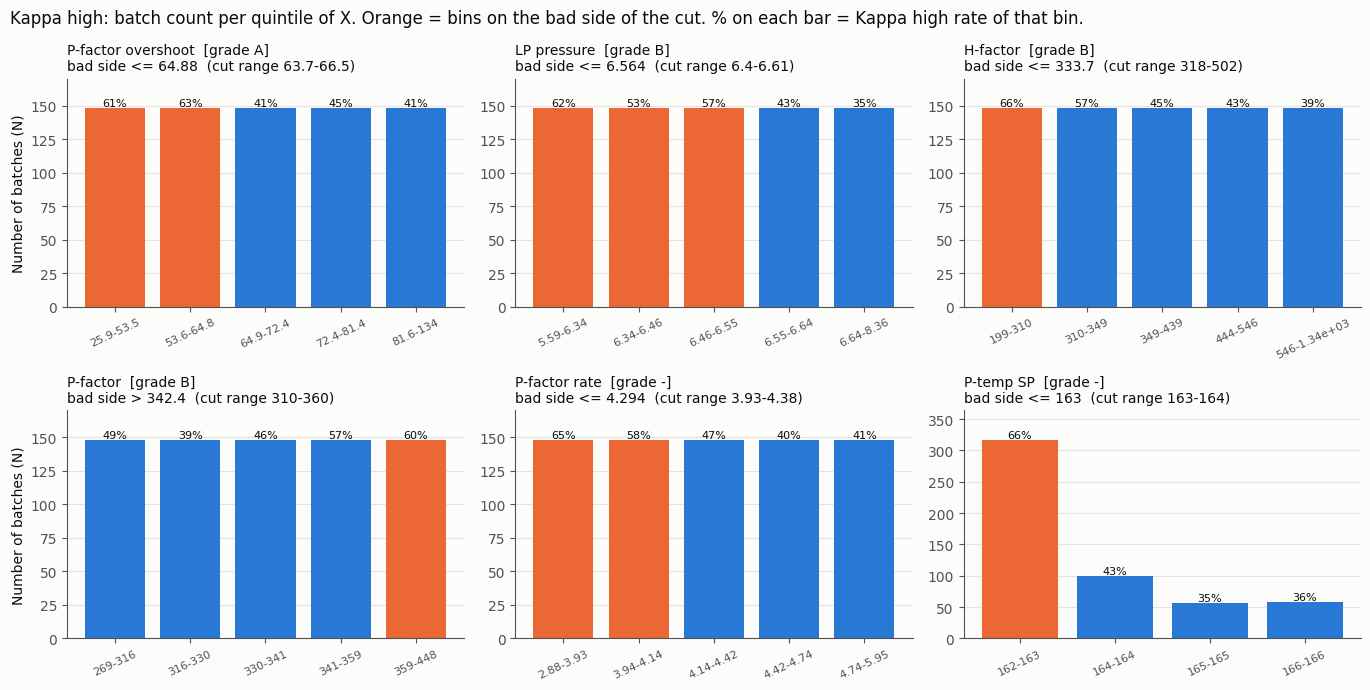

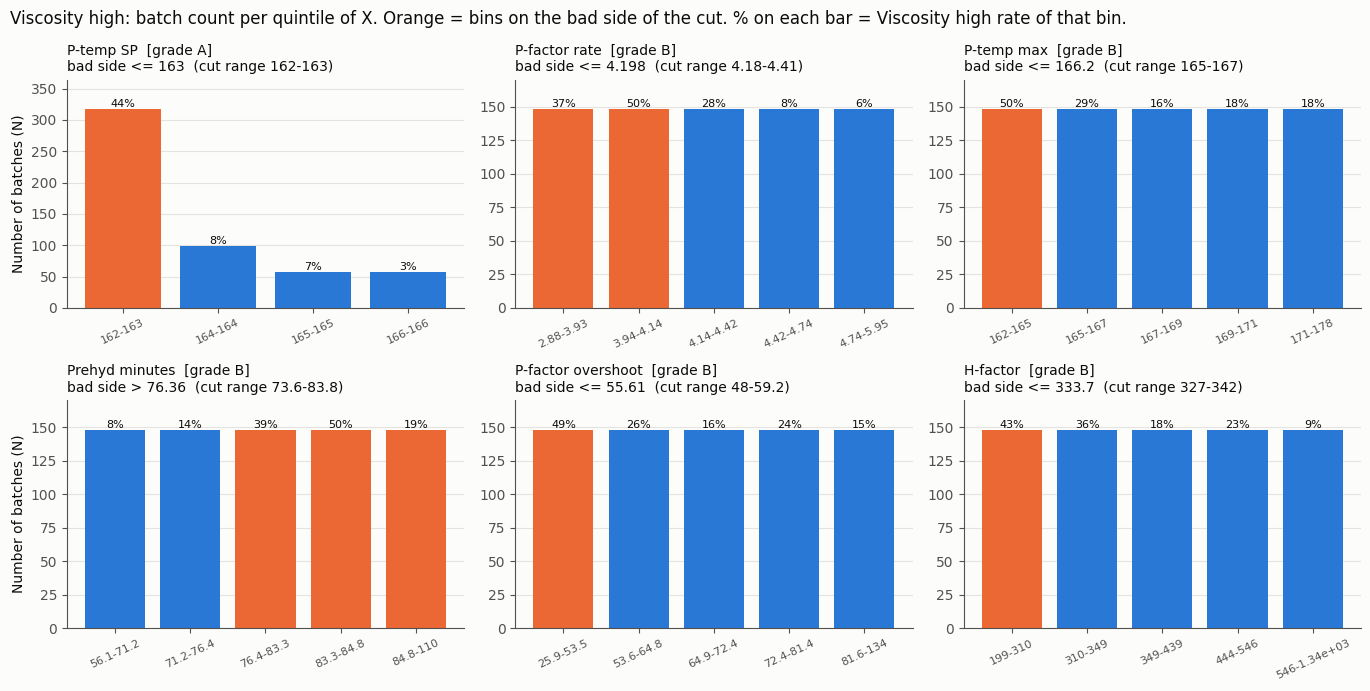

In [ ]:
for event in ["fail", "kappa_high", "visc_high"]:
    plots.count_curves(df, results[event], event)


## Step 6 - Operating window
From the grade A/B rows: a bad side `<=` gives a **lower limit** (keep X above), `>` gives an **upper limit**.
`data_p5 / data_p95` = the range the plant really ran. Where a side has no evidence (e.g. no over-cooking
limit, because Viscosity-low fails are rare), **stay inside the data range** - the data cannot speak beyond it.

In [ ]:
win = golden.window(results, df)
win.round(3)

,X,keep_above,lower_from,keep_at_or_below,upper_from,conflict,data_p5,data_p95
pfactor_overshoot,P-factor overshoot,64.880,Fail QC (any) (A),NaN,,False,39.317,99.714
pfactor_temp_setpoint_last_prehydrolysis,P-temp SP,163.000,Fail QC (any) (A),NaN,,False,162.000,166.000
LP_pressure_mean_heat_and_cook,LP pressure,6.564,Fail QC (any) (B),NaN,,False,6.086,6.877
h_factor,H-factor,333.725,Fail QC (any) (B),NaN,,False,272.934,722.122
alkali_accumulator1_conc_mean_hot_liquor_filling,Alkali conc 1,36.230,Fail QC (any) (B),NaN,,False,35.668,37.996
prehydrolysis_minutes,Prehyd minutes,NaN,,76.358,Viscosity high (B),False,66.698,104.762
pfactor_actual_last_prehydrolysis,P-factor,NaN,,334.180,Fail QC (any) (B),False,299.539,416.591
pfactor_rate,P-factor rate,4.294,Fail QC (any) (B),NaN,,False,3.600,5.055
pfactor_temp_max_prehydrolysis,P-temp max,166.166,Fail QC (any) (B),NaN,,False,163.147,173.113
pfactor_final,P-factor final,425.003,Viscosity high (B),NaN,,False,375.054,510.291


### Combined window check
Rules from `config.GOLDEN_WINDOW_RULES`. A batch is **inside** when it meets every rule.
This is the test of the window itself: fail rate inside vs outside, overall and **month by month**.

Rules: [('pfactor_overshoot', '>', 64.3), ('h_factor', '>', 333.8)]
Fail QC (any)   inside 347 (47%) | fail inside 45% (0.4, 0.5) vs outside 73% (0.68, 0.77) | Fisher p 7.0e-15 | MH RR outside 1.35 (p 0.000) | months 5/6
Kappa high      inside 347 (47%) | fail inside 38% (0.33, 0.43) vs outside 61% (0.56, 0.66) | Fisher p 8.3e-10 | MH RR outside 1.34 (p 0.000) | months 5/6
Viscosity high  inside 347 (47%) | fail inside 13% (0.1, 0.17) vs outside 37% (0.33, 0.42) | Fisher p 6.5e-14 | MH RR outside 1.91 (p 0.000) | months 4/6
Viscosity low   inside 347 (47%) | fail inside 2% (0.01, 0.04) vs outside 2% (0.01, 0.04) | Fisher p 7.9e-01 | MH RR outside 1.04 (p 0.930) | months 2/6
  saved d:\chinnput\DP Cooking ODL Analyzer\DP Cooking ODL Analyzer\XGboost_Model\output\golden_window_months.png


,month,n_outside,fail_outside,n_inside,fail_inside
0,2026-05,12,0.58,66,0.30
1,2026-06,31,0.39,89,0.27
2,2026-07,96,0.75,56,0.45
3,2026-08,97,0.86,57,0.65
4,2026-09,110,0.79,51,0.65
5,2026-10,47,0.53,28,0.57


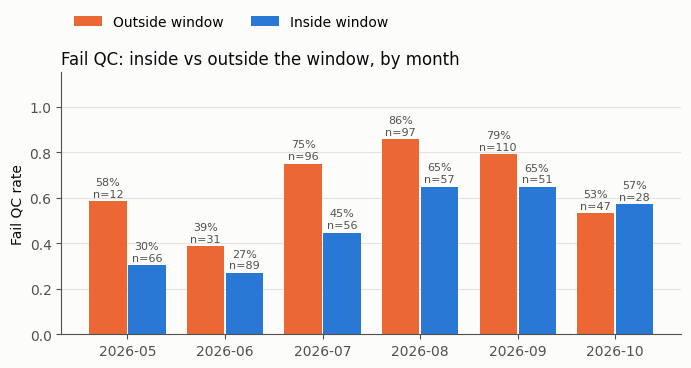

In [ ]:
print("Rules:", config.GOLDEN_WINDOW_RULES)
for event in ["fail", "kappa_high", "visc_high", "visc_low"]:
    s, pm = golden.window_check(df, config.GOLDEN_WINDOW_RULES, event)
    print(f"{golden.OUTCOMES[event]:15s} inside {s['n_inside']} ({s['share_inside']:.0%}) | "
          f"fail inside {s['fail_inside']:.0%} {tuple(round(v, 2) for v in s['fail_inside_ci'])} vs "
          f"outside {s['fail_outside']:.0%} {tuple(round(v, 2) for v in s['fail_outside_ci'])} | "
          f"Fisher p {s['fisher_p']:.1e} | MH RR outside {s['mh_rr_outside']:.2f} (p {s['mh_p']:.3f}) | months {s['months_agree']}")

s, pm = golden.window_check(df, config.GOLDEN_WINDOW_RULES, "fail")
plots.window_months(pm, "Fail QC: inside vs outside the window, by month");
pm.round(2)

## Reading the result
- **Grade A** -> propose a trial / SOP candidate. **B** -> trial to confirm. **C / -** -> do not adjust on this evidence.
- A window says *where the fail rate is lower in history*, not that moving X **causes** it. Check the chemistry, then confirm with a trial (e.g. same week, alternate the setting).
- Viscosity-low fails are rare, so the data has **no upper limit** for cooking strength: never push X beyond `data_p95`.
- Log each run in `update.md`.

## Scatter - P-factor overshoot vs Viscosity
Each dot = one batch. Blue band = Viscosity spec. Dashed line = cut from the screen. Change `X_COL` to look at another X.

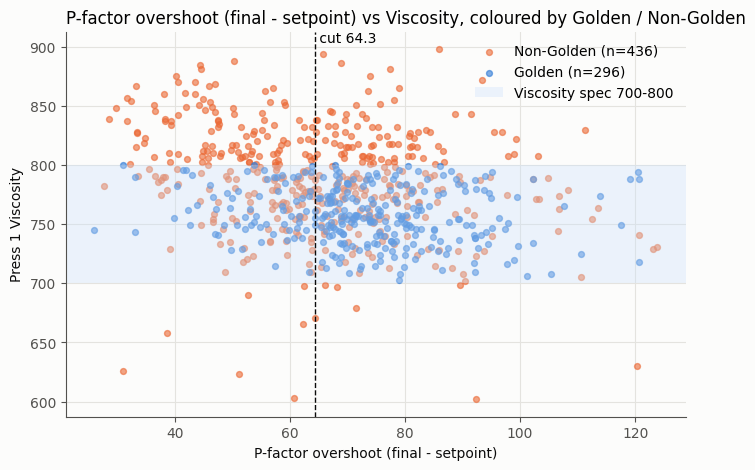

Spearman overshoot vs Viscosity: -0.27


In [ ]:
import matplotlib.pyplot as plt

X_COL, X_LABEL = "pfactor_overshoot", "P-factor overshoot (final - setpoint)"
CUT = 64.3                                          # cut from the golden screen
v_lo, v_hi = config.GOLDEN_SPEC["press1_viscosity"]

d = df[df[X_COL] <= df[X_COL].quantile(0.99)]       # hide the top 1% (up to ~600) so the plot is readable
fig, ax = plt.subplots(figsize=(8, 5))
for flag, name, color in [(0, "Non-Golden", "#eb6834"), (1, "Golden", "#2a78d6")]:
    s = d[d["golden"] == flag]
    ax.scatter(s[X_COL], s["press1_viscosity"], s=18, alpha=0.6, color=color, label=f"{name} (n={len(s)})")
ax.axhspan(v_lo, v_hi, color="#cde2fb", alpha=0.35, lw=0, label=f"Viscosity spec {v_lo}-{v_hi}")
ax.axvline(CUT, color="#0b0b0b", ls="--", lw=1)
ax.text(CUT, ax.get_ylim()[1], f" cut {CUT}", va="top")
ax.set_xlabel(X_LABEL)
ax.set_ylabel("Press 1 Viscosity")
ax.set_title(f"{X_LABEL} vs Viscosity, coloured by Golden / Non-Golden", loc="left")
ax.legend(frameon=False, loc="upper right")
plt.show()
print(f"Spearman overshoot vs Viscosity: {df[[X_COL, 'press1_viscosity']].corr(method='spearman').iloc[0, 1]:+.2f}")